# E-Commerce Exploratory Data Analysis (EDA)

**Objective:** Explore, clean, visualize and analyze the E-commerce dataset to identify patterns in customers, products, categories, sales, profit, discounts and payment modes.

This notebook keeps the original analysis and extends it with additional business-oriented EDA, outlier detection and final insights.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Load Dataset

In [2]:
# Keep the CSV in the same folder as this notebook
df = pd.read_csv("EDA_Ecommerce.csv")
df.head()

,Order_ID,Customer_ID,Order_Date,Age,City,Category,Product_Name,Brand,Quantity,Unit_Price,Discount,Payment_Mode,Customer_Rating,Sales,Profit
0,ORD1082,CUST1004,3/23/2025,19.0,Nashik,Electronics,Wireless Headphones,Samsung,5.0,10508.22,0.15,Net Banking,2.5,44659.94,9665.61
1,ORD1143,CUST1058,5/23/2025,54.0,Kolhapur,Beauty,Shampoo,Lakme,5.0,8880.72,0.02,UPI,4.0,43515.53,4562.30
2,ORD1032,CUST1058,2/1/2025,54.0,Navi Mumbai,Grocery,Dry Fruits,Fortune,2.0,13197.67,0.26,Cash on Delivery,4.2,19532.55,1334.02
3,ORD1030,CUST1033,1/30/2025,21.0,Nagpur,Grocery,Green Tea,Britannia,5.0,4266.03,0.25,Debit Card,2.9,15997.61,2697.00
4,ORD1119,CUST1041,4/29/2025,49.0,Mumbai,Electronics,Bluetooth Speaker,HP,4.0,2170.13,0.21,NaN,4.4,6857.61,786.72


## 3. Basic Dataset Understanding

In [3]:
print("Rows and Columns:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

df.info()

Rows and Columns: (155, 15)

Column Names:
['Order_ID', 'Customer_ID', 'Order_Date', 'Age', 'City', 'Category', 'Product_Name', 'Brand', 'Quantity', 'Unit_Price', 'Discount', 'Payment_Mode', 'Customer_Rating', 'Sales', 'Profit']
<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         155 non-null    str    
 1   Customer_ID      155 non-null    str    
 2   Order_Date       155 non-null    str    
 3   Age              150 non-null    float64
 4   City             149 non-null    str    
 5   Category         155 non-null    str    
 6   Product_Name     155 non-null    str    
 7   Brand            155 non-null    str    
 8   Quantity         148 non-null    float64
 9   Unit_Price       155 non-null    float64
 10  Discount         155 non-null    float64
 11  Payment_Mode     146 non-null    str    
 12  Customer_Rating  155 non-nul

In [4]:
df.describe()

,Age,Quantity,Unit_Price,Discount,Customer_Rating,Sales,Profit
count,150.000000,148.000000,155.000000,155.000000,155.000000,155.000000,155.000000
mean,39.853333,3.567568,8126.239258,0.182516,3.528065,20392.506903,3143.644677
std,13.714435,3.418959,7374.639736,0.101352,0.891629,16921.038322,2698.545134
min,18.000000,1.000000,238.410000,0.000000,2.000000,496.330000,37.680000
25%,28.000000,2.000000,4682.450000,0.085000,2.750000,7583.030000,886.375000
50%,41.000000,3.000000,8108.895000,0.190000,3.550000,16026.040000,2559.305000
75%,50.000000,5.000000,11027.825000,0.265000,4.300000,30641.495000,4624.005000
max,95.000000,30.000000,85000.000000,0.350000,5.000000,125000.000000,13525.550000


In [5]:
df.describe(include="object")

C:\Users\DELL\AppData\Local\Temp\ipykernel_12064\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Order_ID,Customer_ID,Order_Date,City,Category,Product_Name,Brand,Payment_Mode
count,155,155,155,149,155,155,155,146
unique,150,56,150,7,5,22,21,5
top,ORD1102,CUST1060,4/12/2025,Kolhapur,Grocery,Premium Product,Generic,UPI
freq,2,8,2,29,39,35,37,35


## 4. Missing Values and Duplicate Records

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Order_ID           0
Customer_ID        0
Order_Date         0
Age                5
City               6
Category           0
Product_Name       0
Brand              0
Quantity           7
Unit_Price         0
Discount           0
Payment_Mode       9
Customer_Rating    0
Sales              0
Profit             0
dtype: int64

Duplicate rows: 2


## 5. Category and Brand Analysis

In [7]:
print("Number of unique categories:", df["Category"].nunique())
print("\nCategory counts:")
print(df["Category"].value_counts())

print("\nTop brands:")
print(df["Brand"].value_counts().head(10))

Number of unique categories: 5

Category counts:
Category
Grocery        39
Furniture      35
Beauty         33
Electronics    28
Clothing       20
Name: count, dtype: int64

Top brands:
Brand
Generic       37
Fortune       10
Britannia      9
Aashirvaad     8
Maybelline     7
Tata           7
Nivea          7
Dove           7
Sony           7
Samsung        6
Name: count, dtype: int64


In [8]:
category_brand_map = df.groupby("Category")["Brand"].unique()
for category, brands in category_brand_map.items():
    print(category, ":", brands)

Beauty : <StringArray>
['Lakme', 'Maybelline', 'Nivea', 'Dove', 'Mamaearth']
Length: 5, dtype: str
Clothing : <StringArray>
['Allen Solly', 'Roadster', 'H&M', 'Levi's', 'Puma']
Length: 5, dtype: str
Electronics : <StringArray>
['Samsung', 'HP', 'Noise', 'boAt', 'Sony']
Length: 5, dtype: str
Furniture : <StringArray>
['Generic']
Length: 1, dtype: str
Grocery : <StringArray>
['Fortune', 'Britannia', 'Tata', 'Aashirvaad', 'Organic India', 'Generic']
Length: 6, dtype: str


## 6. Data Cleaning

In [9]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing values using simple, explainable rules
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["City"] = df["City"].fillna("Unknown")
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].mean())
df["Payment_Mode"] = df["Payment_Mode"].fillna("Unknown")

print("Remaining missing values:")
print(df.isnull().sum())

Remaining missing values:
Order_ID           0
Customer_ID        0
Order_Date         0
Age                0
City               0
Category           0
Product_Name       0
Brand              0
Quantity           0
Unit_Price         0
Discount           0
Payment_Mode       0
Customer_Rating    0
Sales              0
Profit             0
dtype: int64


In [10]:
# Check invalid customer ratings
invalid_rating = df[(df["Customer_Rating"] < 0) | (df["Customer_Rating"] > 5)]
print("Invalid customer rating records:", len(invalid_rating))
invalid_rating.head()

Invalid customer rating records: 0


,Order_ID,Customer_ID,Order_Date,Age,City,Category,Product_Name,Brand,Quantity,Unit_Price,Discount,Payment_Mode,Customer_Rating,Sales,Profit


In [11]:
# Treat invalid ratings as missing values for rating-based analysis
df.loc[(df["Customer_Rating"] < 0) | (df["Customer_Rating"] > 5), "Customer_Rating"] = np.nan
df["Customer_Rating"] = df["Customer_Rating"].fillna(df["Customer_Rating"].median())
print("Invalid ratings cleaned. Rating range:", df["Customer_Rating"].min(), "to", df["Customer_Rating"].max())

Invalid ratings cleaned. Rating range: 2.0 to 5.0


## 7. Univariate Analysis

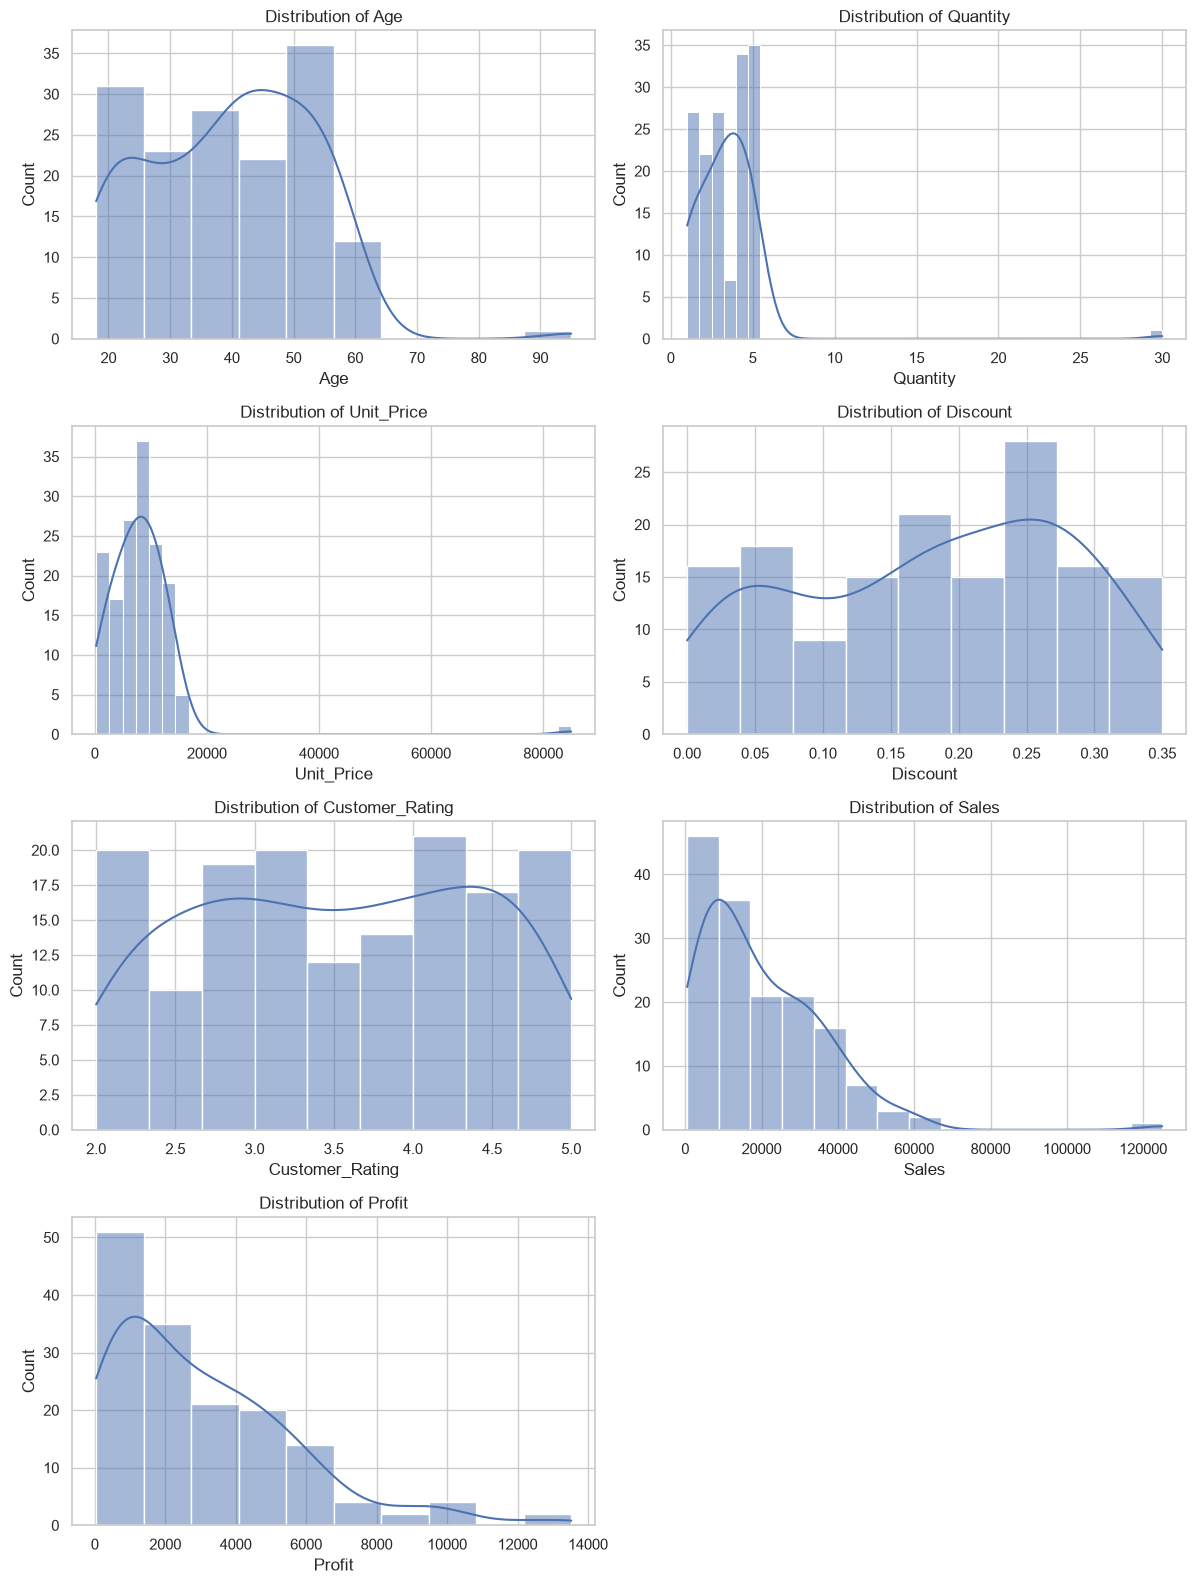

In [12]:
numerical_cols = ["Age", "Quantity", "Unit_Price", "Discount", "Customer_Rating", "Sales", "Profit"]
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
for j in range(len(numerical_cols), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

## 8. Categorical Visualizations

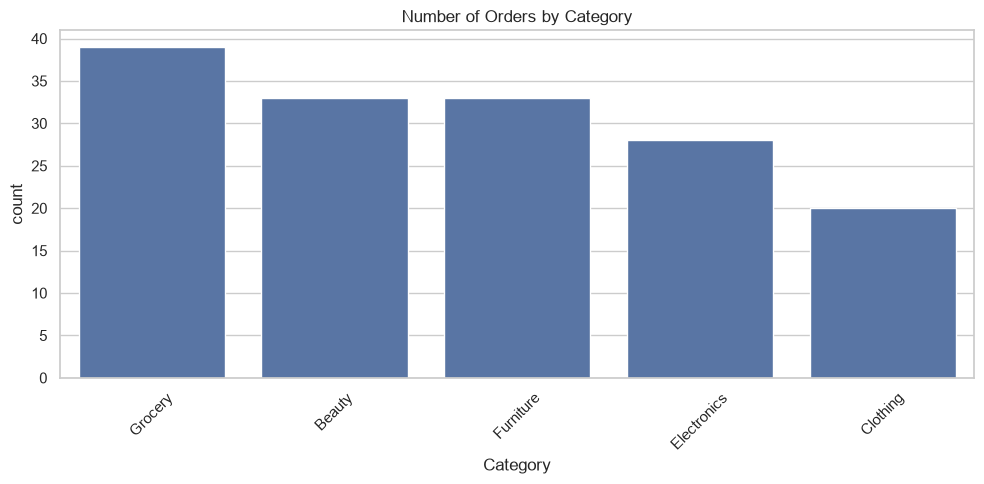

In [13]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="Category", order=df["Category"].value_counts().index)
plt.xticks(rotation=45)
plt.title("Number of Orders by Category")
plt.tight_layout()
plt.show()

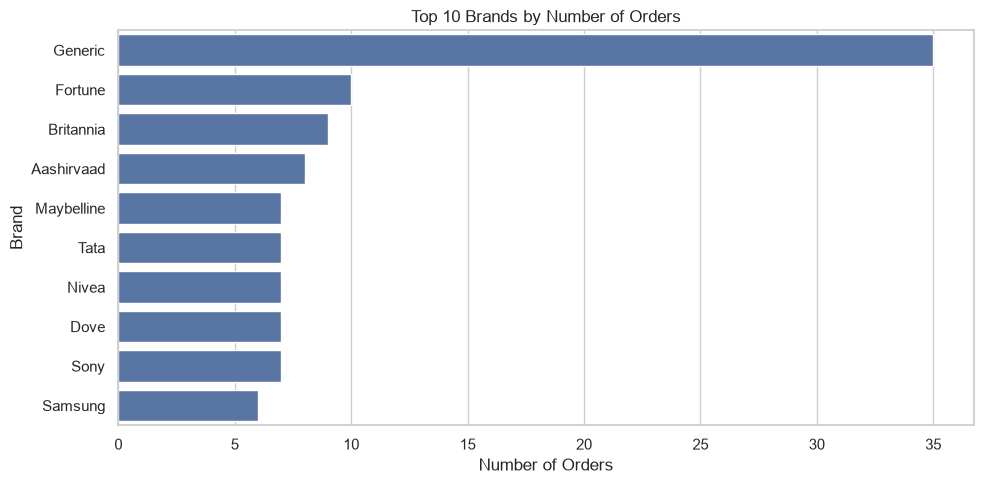

In [14]:
plt.figure(figsize=(10,5))
top_brands = df["Brand"].value_counts().head(10)
sns.barplot(x=top_brands.values, y=top_brands.index)
plt.title("Top 10 Brands by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

## 9. Bivariate Analysis

,Age,Quantity,Unit_Price,Discount,Customer_Rating,Sales,Profit
Age,1.000000,0.112812,0.094953,0.065095,-0.132424,-0.039912,0.031822
Quantity,0.112812,1.000000,-0.030975,0.135016,-0.045166,0.379198,0.416912
Unit_Price,0.094953,-0.030975,1.000000,-0.057295,-0.071832,0.257787,0.283166
Discount,0.065095,0.135016,-0.057295,1.000000,-0.061564,-0.122929,-0.064910
Customer_Rating,-0.132424,-0.045166,-0.071832,-0.061564,1.000000,-0.061203,-0.093661
Sales,-0.039912,0.379198,0.257787,-0.122929,-0.061203,1.000000,0.750822
Profit,0.031822,0.416912,0.283166,-0.064910,-0.093661,0.750822,1.000000


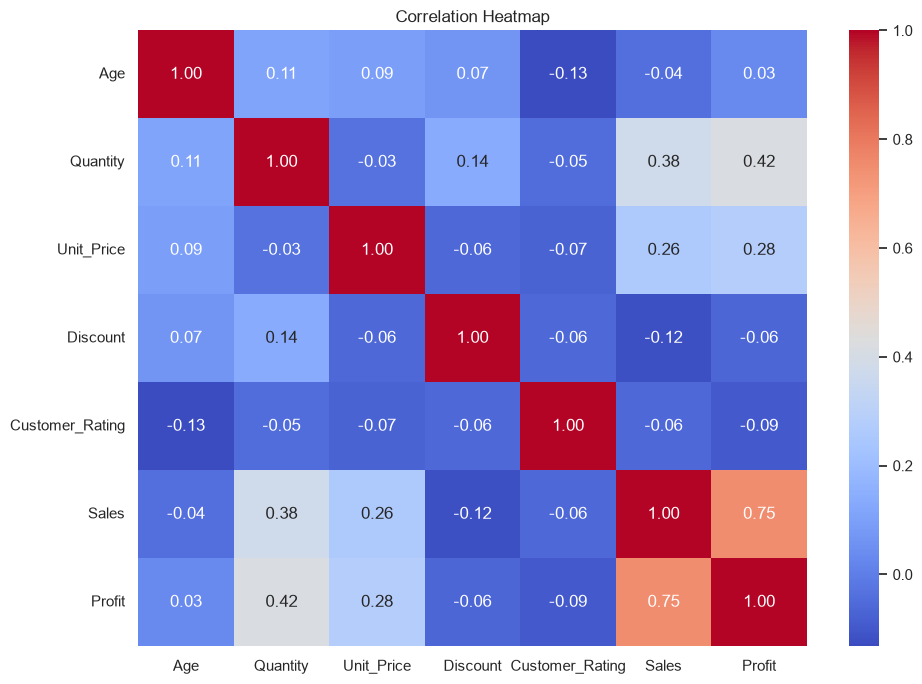

In [15]:
corr = df[numerical_cols].corr()
display(corr)

plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 10. Sales and Profit Analysis

In [16]:
category_sales_profit = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
display(category_sales_profit)

,Sales,Profit
Category,,
Grocery,771151.12,112665.980
Beauty,745601.05,119177.480
Furniture,602555.98,112576.140
Electronics,531829.88,84249.445
Clothing,420396.16,40978.620


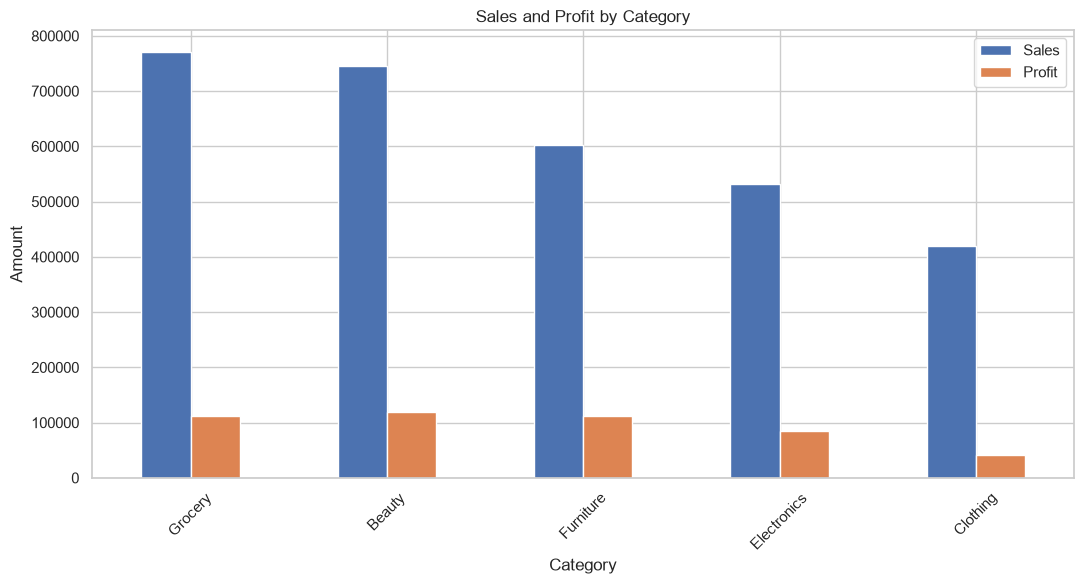

In [17]:
category_sales_profit.plot(kind="bar", figsize=(11,6))
plt.title("Sales and Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

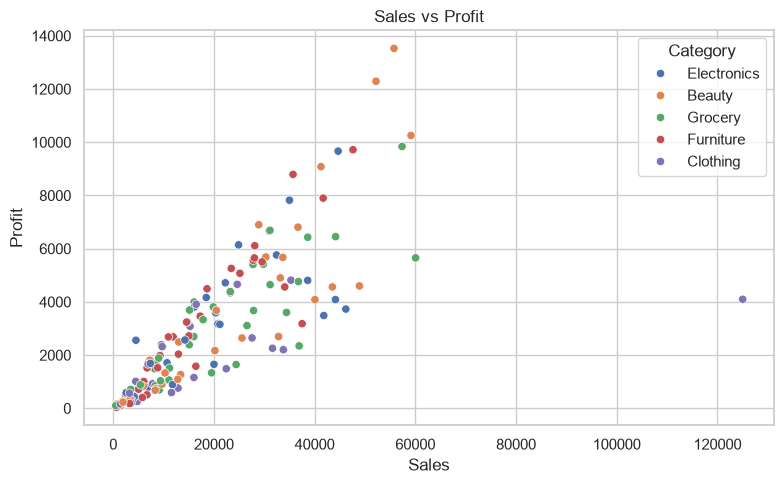

In [18]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Sales", y="Profit", hue="Category")
plt.title("Sales vs Profit")
plt.tight_layout()
plt.show()

## 11. Payment Mode Analysis

Payment_Mode
UPI                 35
Credit Card         31
Debit Card          29
Cash on Delivery    25
Net Banking         24
Unknown              9
Name: count, dtype: int64

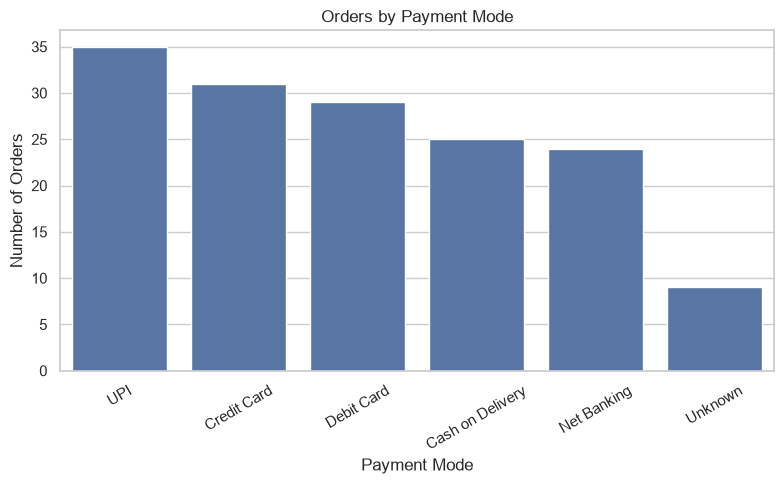

In [19]:
payment_counts = df["Payment_Mode"].value_counts()
display(payment_counts)

plt.figure(figsize=(8,5))
sns.barplot(x=payment_counts.index, y=payment_counts.values)
plt.title("Orders by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 12. City-wise Analysis

City
Kolhapur       641574.36
Pune           574281.54
Satara         406422.31
Navi Mumbai    385713.23
Nashik         354843.70
Mumbai         266275.72
Nagpur         264287.65
Unknown        178135.68
Name: Sales, dtype: float64

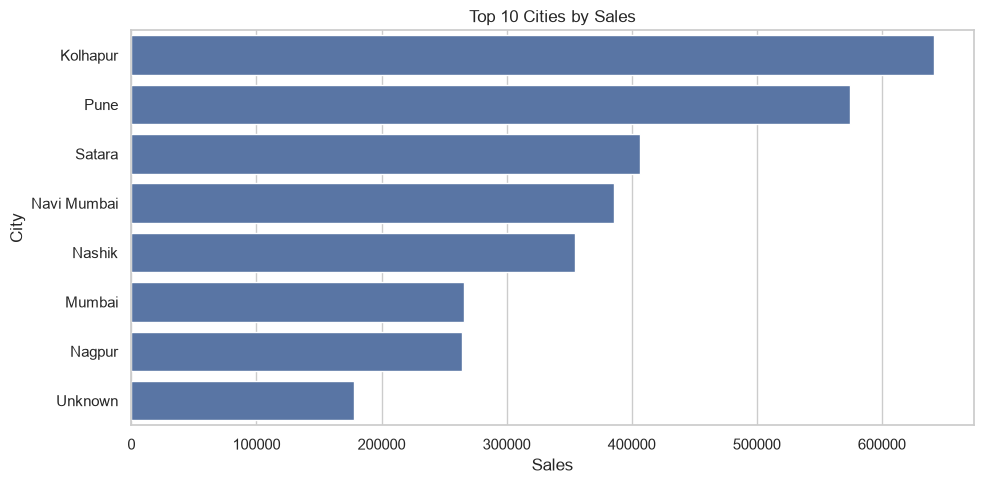

In [20]:
city_sales = df.groupby("City")["Sales"].sum().sort_values(ascending=False).head(10)
display(city_sales)

plt.figure(figsize=(10,5))
sns.barplot(x=city_sales.values, y=city_sales.index)
plt.title("Top 10 Cities by Sales")
plt.xlabel("Sales")
plt.ylabel("City")
plt.tight_layout()
plt.show()

## 13. Customer Rating Analysis

Customer_Rating
2.0    27
3.0    46
4.0    53
5.0    27
Name: count, dtype: int64

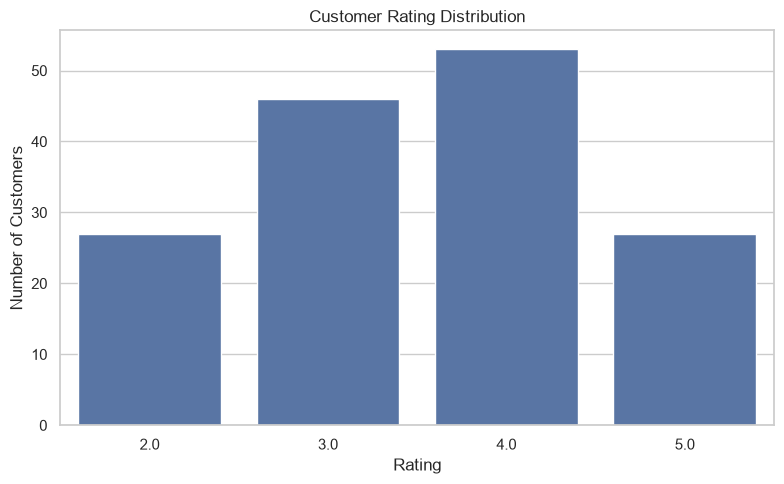

In [21]:
rating_counts = df["Customer_Rating"].round().value_counts().sort_index()
display(rating_counts)

plt.figure(figsize=(8,5))
sns.countplot(x=df["Customer_Rating"].round())
plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## 14. Discount Analysis

In [22]:
discount_summary = df.groupby("Discount")[["Sales", "Profit"]].mean().sort_index()
display(discount_summary)

,Sales,Profit
Discount,,
0.00,27109.995000,4237.225000
0.01,15323.916667,2796.383333
0.02,36087.292000,5620.072000
0.03,28991.405000,5303.417500
0.04,21312.261429,2925.961429
0.05,39805.420000,3162.353333
0.06,14742.525000,2825.300000
0.07,9133.090000,1040.826667
0.08,8497.108000,1510.478000


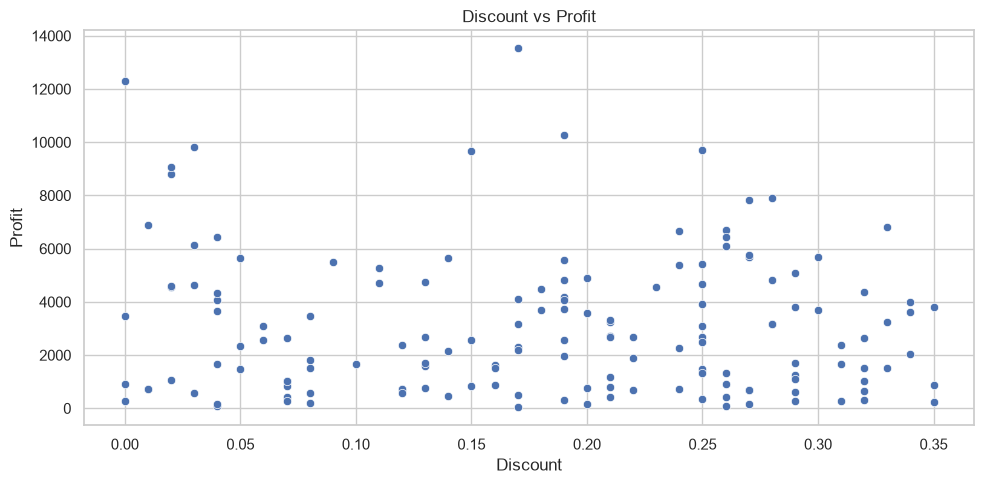

In [23]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df, x="Discount", y="Profit")
plt.title("Discount vs Profit")
plt.tight_layout()
plt.show()

## 15. Quantity Analysis

In [24]:
quantity_summary = df.groupby("Quantity")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
display(quantity_summary.head(10))

,Sales,Profit
Quantity,,
5.000000,1050775.85,157933.140
4.000000,882269.22,125995.330
3.000000,459100.72,80006.570
2.000000,304414.09,48001.870
1.000000,182136.92,28019.575
3.376712,145220.94,19973.540
30.000000,47616.45,9717.640


## 16. Top Products

In [25]:
top_products_sales = df.groupby("Product_Name")["Sales"].sum().sort_values(ascending=False).head(10)
top_products_profit = df.groupby("Product_Name")["Profit"].sum().sort_values(ascending=False).head(10)

print("Top 10 Products by Sales")
display(top_products_sales)

print("Top 10 Products by Profit")
display(top_products_profit)

Top 10 Products by Sales


Product_Name
Premium Product        602555.98
Shampoo                313045.13
Green Tea              225857.34
Basmati Rice           167658.13
Bluetooth Speaker      166550.68
Dry Fruits             159144.58
Moisturizer            158724.92
Kurti                  147191.94
Perfume                136699.02
Wireless Headphones    123461.76
Name: Sales, dtype: float64

Top 10 Products by Profit


Product_Name
Premium Product        112576.14
Shampoo                 42651.52
Green Tea               37283.31
Moisturizer             28090.23
Bluetooth Speaker       26071.90
Perfume                 23128.01
Dry Fruits              23121.74
Basmati Rice            18601.99
Hoodie                  17642.51
Wireless Headphones     17595.69
Name: Profit, dtype: float64

## 17. Outlier Detection using IQR

In [26]:
outlier_summary = []
for col in ["Age", "Quantity", "Unit_Price", "Discount", "Customer_Rating", "Sales", "Profit"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, q1, q3, lower, upper, count])

outlier_df = pd.DataFrame(outlier_summary, columns=["Column", "Q1", "Q3", "Lower Bound", "Upper Bound", "Outlier Count"])
display(outlier_df)

,Column,Q1,Q3,Lower Bound,Upper Bound,Outlier Count
0,Age,28.00,50.00,-5.000,83.000,1
1,Quantity,2.00,4.00,-1.000,7.000,1
2,Unit_Price,4609.80,10946.59,-4895.385,20451.775,1
3,Discount,0.08,0.26,-0.190,0.530,0
4,Customer_Rating,2.70,4.30,0.300,6.700,0
5,Sales,7375.78,30307.29,-27021.485,64704.555,1
6,Profit,880.41,4562.30,-4642.425,10085.135,3


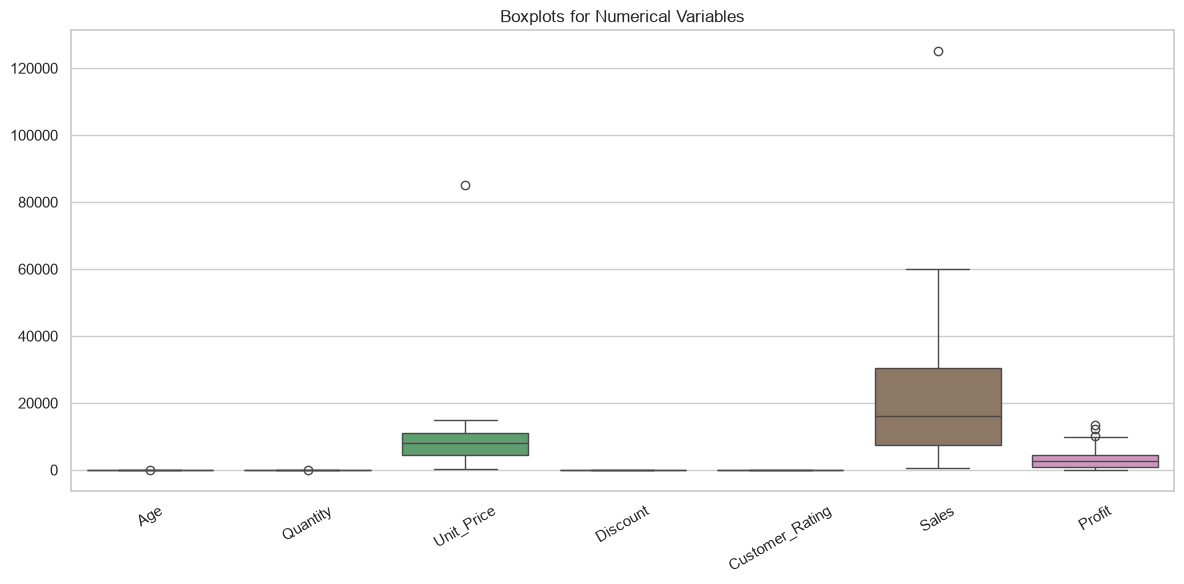

In [27]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df[["Age", "Quantity", "Unit_Price", "Discount", "Customer_Rating", "Sales", "Profit"]])
plt.title("Boxplots for Numerical Variables")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 18. Overall Business Summary

In [36]:
print("===== E-COMMERCE EDA SUMMARY =====")
print("Total records:", len(df))
print("Total sales:", round(df["Sales"].sum(), 2))
print("Total profit:", round(df["Profit"].sum(), 2))
print("Average customer rating:", round(df["Customer_Rating"].mean(), 2))
print("Most frequent category:", df["Category"].value_counts().idxmax())
print("Top brand by order count:", df["Brand"].value_counts().idxmax())
print("Top product by sales:", df.groupby("Product_Name")["Sales"].sum().idxmax())
print("Top city by sales:", df.groupby("City")["Sales"].sum().idxmax())
print("Most used payment mode:", df["Payment_Mode"].value_counts().idxmax())

===== E-COMMERCE EDA SUMMARY =====
Total records: 153
Total sales: 3071534.19
Total profit: 469647.66
Average customer rating: 3.52
Most frequent category: Grocery
Top brand by order count: Generic
Top product by sales: Premium Product
Top city by sales: Kolhapur
Most used payment mode: UPI


## 19. Key Insights and Conclusion

After running the notebook, use the generated tables and charts to describe: **(1)** which categories and products contribute most to sales, **(2)** which categories/products contribute most to profit, **(3)** the most common payment mode, **(4)** the strongest sales cities, **(5)** customer-rating patterns, **(6)** whether discounts appear to affect profit, and **(7)** which numerical columns contain important outliers.

### Conclusion
The E-commerce EDA project cleans the dataset, handles missing and duplicate records, checks data quality, explores numerical and categorical variables, studies relationships between important business measures, identifies top-performing categories/brands/products, and detects outliers. The final charts and summary values can be used to support data-driven business decisions.